# Cell 0 — Stage 8: Silt / Sediment Detection using DSM & DTM

**Concept:** DSM (surface model) captures ground + objects on top.  
DTM (terrain model) captures bare ground only.  
`CHM = DSM - DTM` gives height-above-ground.  
Inside canal mask: CHM ≈ 0 → water/clear; CHM > threshold → silt/sediment deposit.

| Cell | Purpose | Time |
|------|---------|------|
| 0 | Header | - |
| 1 | Config & imports | ~2s |
| 2 | Load canal masks from Cell 07 outputs | ~10s |
| 3 | Compute CHM per mosaic, extract silt within canal | ~2 min |
| 4 | Per-reach silt quantification | ~1 min |
| 5 | Visualize silt map + bounding boxes | ~1 min |
| 6 | Summary table + export GeoTIFF | ~30s |

**Input:** DSM/DTM TIFs from `TLBC_DSM_DTM/` + canal masks from `07_blockage` outputs  
**Output:** Silt map GeoTIFF, per-reach silt depth & volume estimates

In [2]:
# Cell 1 — Config & imports
import os, gc, json, warnings
warnings.filterwarnings('ignore')

import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio import warp
from rasterio.transform import from_bounds
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy import ndimage
from skimage.morphology import skeletonize

DATA_DIR  = r'D:/Github/Canal Pipeline/TLBC_DSM_DTM/'
DSM_DIR   = r'D:/Github/Canal Pipeline/TLBC_DSM_DTM/TLBC_DSM_DTM'
OUT_07    = os.path.join(DATA_DIR, 'outputs', '07_blockage')
OUT_DIR   = os.path.join(DATA_DIR, 'outputs', '08_silt')
os.makedirs(OUT_DIR, exist_ok=True)

DS = 8
THRESHOLD = 0.4

# ── Silt depth categories (metres) ──
# CHM = DSM - DTM inside canal
# < 0.05m  → noise/water → CLEAR (green)
# 0.00–0.20m → LOW silt (green)
# 0.20–0.50m  → MODERATE silt (orange)
# > 0.50m    → HEAVY silt (red)
# > 2.0m    → likely vegetation, not silt → excluded

SILT_LOW_MAX  = 0.20   # 0.00–0.20 = green (green)
SILT_MOD_MAX  = 0.50   # 0.20–0.50 = orange (orange)
SILT_VEG_MAX  = 2.00   # > 2.0m = vegetation, excluded

ALL_TAGS = {
    'ATTANUR_1': (r'D:/Github/Canal Pipeline/TLBC_DSM_DTM/TLBC_D95_ATTANUR_1_ortho.tif', 0.0462),
    'ATTANUR_2': (os.path.join(DATA_DIR, 'TLBC_D95_ATTANUR_2_ortho.tif'), 0.0462),
    'ATTANUR_3': (r'D:/Github/Canal Pipeline/TLBC_DSM_DTM/TLBC_D95_ATTANUR_3_ortho.tif', 0.0462),
    'ATTANUR_4': (r'D:/Github/Canal Pipeline/TLBC_DSM_DTM/TLBC_D95_ATTANUR_4_ortho.tif', 0.0352),
}

DSM_FILES = {
    tag: (
        os.path.join(DSM_DIR, f'TLBC_D95_{tag}_dsm.tif'),
        os.path.join(DSM_DIR, f'TLBC_D95_{tag}_dtm.tif'),
    )
    for tag in ALL_TAGS
}

print('Silt depth categories:')
print(f'  GREEN:  < {SILT_LOW_MAX}m (clear / low silt)')
print(f'  ORANGE: {SILT_LOW_MAX}–{SILT_MOD_MAX}m (moderate silt)')
print(f'  RED:    > {SILT_MOD_MAX}m (heavy silt, up to {SILT_VEG_MAX}m)')
print(f'\nTags: {list(ALL_TAGS.keys())}')
for tag, (dsm, dtm) in DSM_FILES.items():
    ok = 'ok' if os.path.exists(dsm) and os.path.exists(dtm) else 'MISSING'
    print(f'  {tag}: {ok}')

Silt depth categories:
  GREEN:  < 0.2m (clear / low silt)
  ORANGE: 0.2–0.5m (moderate silt)
  RED:    > 0.5m (heavy silt, up to 2.0m)

Tags: ['ATTANUR_1', 'ATTANUR_2', 'ATTANUR_3', 'ATTANUR_4']
  ATTANUR_1: ok
  ATTANUR_2: ok
  ATTANUR_3: ok
  ATTANUR_4: ok


In [3]:
# Cell 2 — Load cleaned canal-only masks saved by Cell 07
# Uses binary canal-only masks from 07 Cell 2b so FICs are excluded from silt analysis.

canal_data = {}

for tag, (ortho_path, px_m) in ALL_TAGS.items():
    clean_path = os.path.join(OUT_07, f'{tag}_canal_only_mask.npz')
    mask_path = clean_path if os.path.exists(clean_path) else os.path.join(OUT_07, f'{tag}_canal_mask.npz')
    if not os.path.exists(mask_path):
        print(f'  SKIP {tag} — canal mask not found at {mask_path}')
        print('         Run 07_blockage_detection.ipynb Cell 2/2b first.')
        continue

    saved = np.load(mask_path)
    if 'binary' in saved.files:
        canal_clean = saved['binary'].astype(np.uint8)
        source = 'binary canal-only mask'
    else:
        canal_prob = saved['prob']
        canal_clean = (canal_prob > THRESHOLD).astype(np.uint8)
        source = 'probability fallback mask'

    fic_candidate = saved['fic_candidate'].astype(np.uint8) if 'fic_candidate' in saved.files else np.zeros_like(canal_clean, dtype=np.uint8)
    out_h, out_w = canal_clean.shape

    with rasterio.open(ortho_path) as src:
        crs = src.crs
        ortho_transform = src.transform

    mask_transform = rasterio.transform.Affine(
        ortho_transform.a * DS, ortho_transform.b, ortho_transform.c,
        ortho_transform.d, ortho_transform.e * DS, ortho_transform.f
    )

    canal_data[tag] = {
        'canal_mask': canal_clean,
        'fic_candidate': fic_candidate,
        'transform':  mask_transform,
        'crs':        crs,
        'px_m':       px_m,
        'px_m_mask':  px_m * DS,
        'ortho_path': ortho_path,
        'shape':      (out_h, out_w),
    }
    print(f'  {tag}: {source} {out_w}x{out_h} loaded | FIC pixels excluded: {int(fic_candidate.sum())}')
    del saved
    gc.collect()

print(f'\nLoaded cleaned canal-only masks for {len(canal_data)} mosaics')


  ATTANUR_1: binary canal-only mask 4054x6498 loaded | FIC pixels excluded: 165
  ATTANUR_2: binary canal-only mask 9960x17199 loaded | FIC pixels excluded: 506
  ATTANUR_3: binary canal-only mask 7864x17380 loaded | FIC pixels excluded: 421
  ATTANUR_4: binary canal-only mask 2212x5470 loaded | FIC pixels excluded: 0

Loaded cleaned canal-only masks for 4 mosaics


In [4]:
# Cell 3 — Compute CHM (DSM - DTM), classify silt by depth, pixel-level map
#
# Categories:  GREEN < 0.2m  |  ORANGE 0.2–0.5m  |  RED > 0.5m  |  excluded > 2.0m (vegetation)

silt_data = {}

for tag, cdata in canal_data.items():
    print(f'\n{"="*55}')
    print(f'{tag} ...')

    dsm_path, dtm_path = DSM_FILES[tag]
    canal_mask = cdata['canal_mask']
    mask_h, mask_w = cdata['shape']
    mask_transform = cdata['transform']
    crs = cdata['crs']

    # ── Reproject DSM & DTM to canal mask grid ──
    with rasterio.open(dsm_path) as dsrc:
        dsm_full, _ = warp.reproject(
            source=rasterio.band(dsrc, 1),
            destination=np.zeros((mask_h, mask_w), dtype=np.float32),
            src_transform=dsrc.transform, src_crs=dsrc.crs,
            dst_transform=mask_transform, dst_crs=crs,
            resampling=warp.Resampling.bilinear,
            src_nodata=dsrc.nodata, dst_nodata=-9999.0,
        )

    with rasterio.open(dtm_path) as dsrc:
        dtm_full, _ = warp.reproject(
            source=rasterio.band(dsrc, 1),
            destination=np.zeros((mask_h, mask_w), dtype=np.float32),
            src_transform=dsrc.transform, src_crs=dsrc.crs,
            dst_transform=mask_transform, dst_crs=crs,
            resampling=warp.Resampling.bilinear,
            src_nodata=dsrc.nodata, dst_nodata=-9999.0,
        )

    # ── CHM = DSM - DTM ──
    valid = (dsm_full != -9999.0) & (dtm_full != -9999.0)
    chm = np.where(valid, dsm_full - dtm_full, np.nan).astype(np.float32)
    del dsm_full, dtm_full
    gc.collect()

    canal_chm = chm[canal_mask > 0]
    canal_chm_valid = canal_chm[np.isfinite(canal_chm)]
    print(f'  CHM range (all): {np.nanmin(chm):.2f} — {np.nanmax(chm):.2f}m')
    if canal_chm_valid.size > 0:
        print(f'  CHM in canal: mean={np.mean(canal_chm_valid):.3f}m, '
              f'median={np.median(canal_chm_valid):.3f}m')

    # ── Per-pixel silt category (inside canal only) ──
    # 0 = not canal
    # 1 = clear/low  (CHM < 0.2m)    → GREEN
    # 2 = moderate   (0.2–0.5m)      → ORANGE
    # 3 = heavy      (0.5–2.0m)      → RED
    # CHM > 2.0m or < 0.05m noise excluded from silt
    in_canal = canal_mask > 0
    chm_valid = np.isfinite(chm)

    silt_cat = np.zeros((mask_h, mask_w), dtype=np.uint8)
    silt_cat[in_canal & chm_valid & (chm < SILT_LOW_MAX)]  = 1  # green
    silt_cat[in_canal & chm_valid & (chm >= SILT_LOW_MAX) & (chm < SILT_MOD_MAX)] = 2  # orange
    silt_cat[in_canal & chm_valid & (chm >= SILT_MOD_MAX) & (chm <= SILT_VEG_MAX)] = 3  # red
    # CHM > SILT_VEG_MAX → likely vegetation, mark as 0 (excluded)

    px_area = cdata['px_m_mask'] ** 2
    n_green  = int((silt_cat == 1).sum())
    n_orange = int((silt_cat == 2).sum())
    n_red    = int((silt_cat == 3).sum())
    n_canal  = int(in_canal.sum())

    print(f'  Canal pixels: {n_canal}')
    print(f'  GREEN  (< {SILT_LOW_MAX}m):       {n_green} ({n_green/max(1,n_canal)*100:.1f}%)')
    print(f'  ORANGE ({SILT_LOW_MAX}–{SILT_MOD_MAX}m): {n_orange} ({n_orange/max(1,n_canal)*100:.1f}%)')
    print(f'  RED    (> {SILT_MOD_MAX}m):       {n_red} ({n_red/max(1,n_canal)*100:.1f}%)')

    # Mean depth for moderate+heavy silt
    silt_px = (silt_cat >= 2)
    silt_depths = chm[silt_px & chm_valid]
    mean_depth = float(np.nanmean(silt_depths)) if silt_depths.size > 0 else 0.0
    silt_area = (n_orange + n_red) * px_area

    print(f'  Silt area (moderate+heavy): {silt_area:.1f} m²')
    print(f'  Mean silt depth (mod+heavy): {mean_depth:.3f}m')

    silt_data[tag] = {
        'chm':         chm,
        'silt_cat':    silt_cat,
        'n_green':     n_green,
        'n_orange':    n_orange,
        'n_red':       n_red,
        'n_canal':     n_canal,
        'silt_area_m2':float(silt_area),
        'canal_area_m2': float(n_canal * px_area),
        'mean_depth_m': mean_depth,
        'px_m_mask':   cdata['px_m_mask'],
    }

print(f'\nSilt detection complete for {len(silt_data)} mosaics.')


ATTANUR_1 ...
  CHM range (all): -2.12 — 16.42m
  CHM in canal: mean=0.028m, median=0.000m
  Canal pixels: 3244
  GREEN  (< 0.2m):       3070 (94.6%)
  ORANGE (0.2–0.5m): 141 (4.3%)
  RED    (> 0.5m):       33 (1.0%)
  Silt area (moderate+heavy): 23.8 m²
  Mean silt depth (mod+heavy): 0.371m

ATTANUR_2 ...
  CHM range (all): -4.50 — 23.89m
  CHM in canal: mean=1.117m, median=0.272m
  Canal pixels: 128582
  GREEN  (< 0.2m):       61907 (48.1%)
  ORANGE (0.2–0.5m): 12267 (9.5%)
  RED    (> 0.5m):       25833 (20.1%)
  Silt area (moderate+heavy): 5204.6 m²
  Mean silt depth (mod+heavy): 0.912m

ATTANUR_3 ...
  CHM range (all): -3.03 — 29.54m
  CHM in canal: mean=0.166m, median=0.000m
  Canal pixels: 142735
  GREEN  (< 0.2m):       126234 (88.4%)
  ORANGE (0.2–0.5m): 4705 (3.3%)
  RED    (> 0.5m):       7902 (5.5%)
  Silt area (moderate+heavy): 1722.2 m²
  Mean silt depth (mod+heavy): 0.807m

ATTANUR_4 ...
  CHM range (all): -1.61 — 21.85m
  CHM in canal: mean=0.288m, median=0.152m
  Cana

In [5]:
# Cell 4 — Per-reach silt quantification using silt_cat from Cell 3

from skimage.morphology import skeletonize

DS_A = 4
REACH_LEN_PX = 80

silt_reaches = {}

for tag, cdata in canal_data.items():
    print(f'\n{"="*55}')
    print(f'{tag} ...')

    canal_mask = cdata['canal_mask']
    silt_cat   = silt_data[tag]['silt_cat']
    chm        = silt_data[tag]['chm']
    h, w       = canal_mask.shape
    px_m_a     = cdata['px_m_mask'] * DS_A

    h_s, w_s = h // DS_A, w // DS_A
    canal_s  = cv2.resize(canal_mask, (w_s, h_s), interpolation=cv2.INTER_NEAREST)
    cat_s    = cv2.resize(silt_cat,   (w_s, h_s), interpolation=cv2.INTER_NEAREST)
    chm_s    = cv2.resize(chm,        (w_s, h_s), interpolation=cv2.INTER_LINEAR)

    skel = skeletonize(canal_s > 0).astype(np.uint8)
    n_cc, labels_s = cv2.connectedComponents(canal_s, connectivity=8)
    sr, sc = np.where(skel > 0)
    sl = labels_s[sr, sc]

    reaches = []
    for cid in range(1, n_cc):
        m = sl == cid
        cr, cc_arr = sr[m], sc[m]
        if len(cr) < 5:
            continue
        pts = np.column_stack([cr, cc_arr])
        n_r = max(1, len(pts) // REACH_LEN_PX)

        for ri in range(n_r):
            s_idx = ri * REACH_LEN_PX
            e_idx = min((ri + 1) * REACH_LEN_PX, len(pts))
            rp = pts[s_idx:e_idx]

            rmin = max(0, rp[:,0].min() - 5)
            cmin = max(0, rp[:,1].min() - 5)
            rmax = min(h_s, rp[:,0].max() + 5)
            cmax = min(w_s, rp[:,1].max() + 5)

            canal_patch = (labels_s[rmin:rmax, cmin:cmax] == cid)
            cat_patch   = cat_s[rmin:rmax, cmin:cmax]
            canal_px    = int(canal_patch.sum())
            if canal_px < 5:
                continue

            n_g = int(((cat_patch == 1) & canal_patch).sum())
            n_o = int(((cat_patch == 2) & canal_patch).sum())
            n_r_px = int(((cat_patch == 3) & canal_patch).sum())

            # Dominant category for this reach
            if n_r_px > canal_px * 0.2:
                silt_status = 'heavy'
            elif n_o > canal_px * 0.2:
                silt_status = 'moderate'
            elif (n_o + n_r_px) > canal_px * 0.05:
                silt_status = 'light'
            else:
                silt_status = 'clear'

            chm_vals = chm_s[rmin:rmax, cmin:cmax][
                canal_patch & (cat_patch >= 2) & np.isfinite(chm_s[rmin:rmax, cmin:cmax])
            ]
            mean_depth = float(np.nanmean(chm_vals)) if chm_vals.size > 0 else 0.0
            length_m = len(rp) * px_m_a
            silt_vol = (n_o + n_r_px) * (px_m_a ** 2) * mean_depth

            reaches.append({
                'canal_id':    int(cid),
                'reach_idx':   ri,
                'bbox':        (rmin*DS_A, cmin*DS_A, min(h,rmax*DS_A), min(w,cmax*DS_A)),
                'bbox_s':      (rmin, cmin, rmax, cmax),
                'center':      (int(rp[:,0].mean()*DS_A), int(rp[:,1].mean()*DS_A)),
                'length_m':    float(length_m),
                'green_frac':  float(n_g / canal_px),
                'orange_frac': float(n_o / canal_px),
                'red_frac':    float(n_r_px / canal_px),
                'mean_depth_m':float(mean_depth),
                'silt_vol_m3': float(silt_vol),
                'silt_status': silt_status,
            })

    if reaches:
        centers = np.array([[r['center'][0], r['center'][1]] for r in reaches], dtype=np.float32)
        centered = centers - centers.mean(axis=0, keepdims=True)
        if len(reaches) >= 2:
            _, _, vh = np.linalg.svd(centered, full_matrices=False)
            proj = centered @ vh[0]
        else:
            proj = centers[:, 0]
        ch = 0.0
        for seq, idx in enumerate(np.argsort(proj)):
            r = reaches[int(idx)]
            r['global_reach_idx'] = int(seq)
            r['chainage_m'] = ch
            r['chainage_start_m'] = ch
            ch += r['length_m']
            r['chainage_end_m'] = ch

    silt_reaches[tag] = reaches
    sc_counts = {}
    for r in reaches:
        sc_counts[r['silt_status']] = sc_counts.get(r['silt_status'], 0) + 1
    print(f'  {len(reaches)} reaches: {sc_counts}')

print(f'\nPer-reach silt complete.')


ATTANUR_1 ...
  6 reaches: {'clear': 5, 'moderate': 1}

ATTANUR_2 ...
  75 reaches: {'heavy': 15, 'clear': 45, 'light': 13, 'moderate': 2}

ATTANUR_3 ...
  36 reaches: {'light': 16, 'clear': 15, 'heavy': 4, 'moderate': 1}

ATTANUR_4 ...
  2 reaches: {'clear': 1, 'heavy': 1}

Per-reach silt complete.


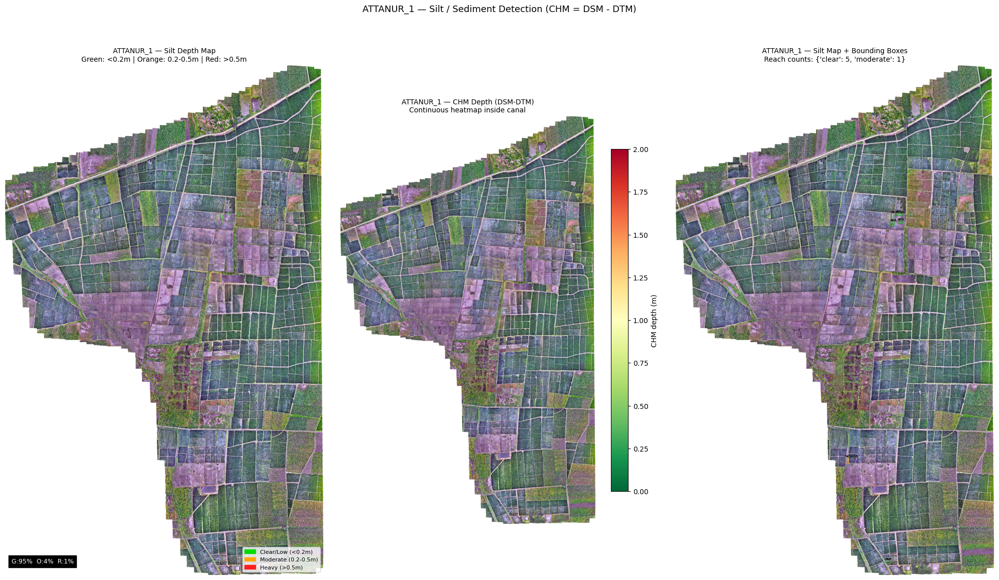

  Saved: ATTANUR_1_silt_map.png


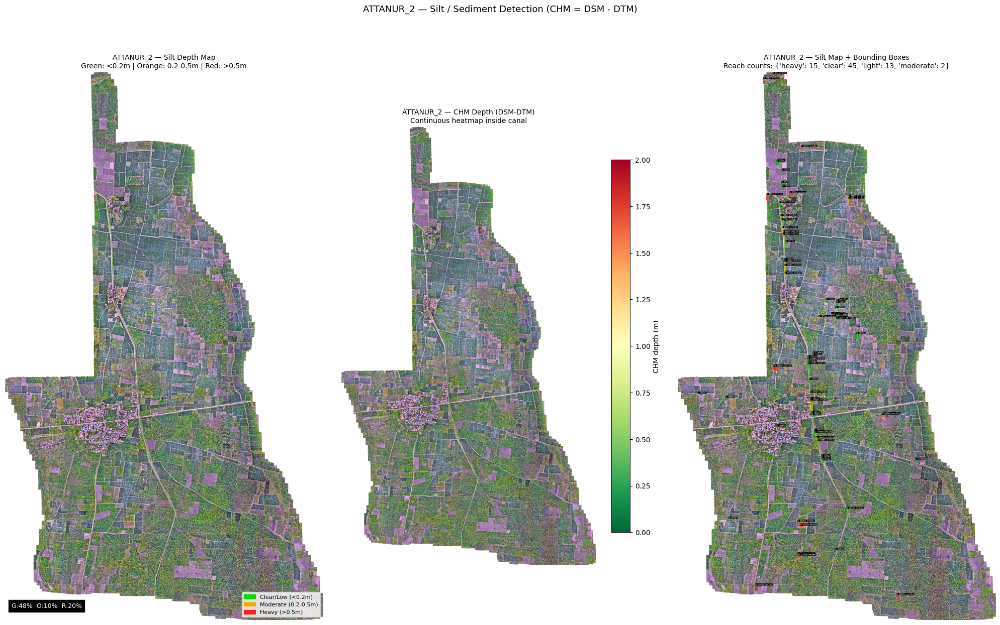

  Saved: ATTANUR_2_silt_map.png


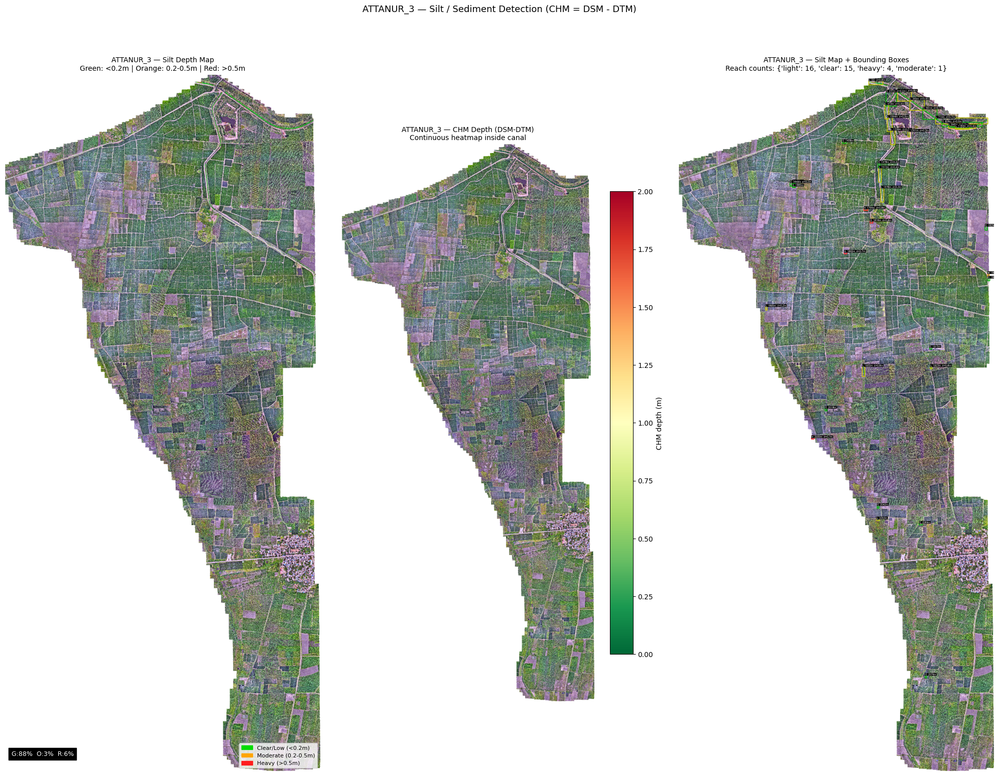

  Saved: ATTANUR_3_silt_map.png


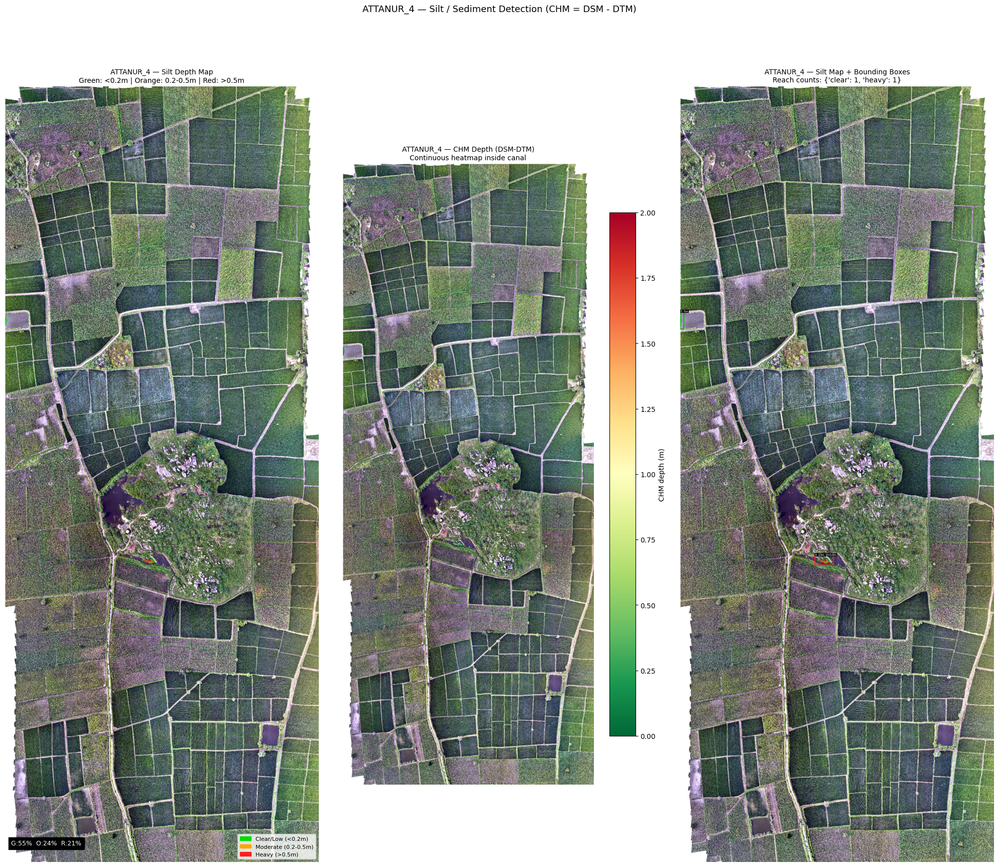

  Saved: ATTANUR_4_silt_map.png


In [6]:
# Cell 5 — Visualize: pixel-level silt map (green/orange/red on canal) + CHM heatmap

VIS_MAX = 2500

# RGB colors for each category
CAT_COLORS = {
    1: np.array([0, 220, 0]),     # GREEN  — clear / low silt (<0.2m)
    2: np.array([255, 165, 0]),   # ORANGE — moderate silt ({SILT_LOW_MAX}–{SILT_MOD_MAX}m)
    3: np.array([255, 30, 30]),   # RED    — heavy silt (>0.5m)
}

def cstretch(rgb, valid):
    out = np.zeros_like(rgb, dtype=np.uint8)
    for c in range(3):
        ch = rgb[:,:,c].astype(np.float64)
        vp = ch[valid]
        if vp.size < 100: continue
        lo, hi = np.percentile(vp, [2, 98])
        if hi - lo < 5: continue
        out[:,:,c] = np.clip((ch-lo)/(hi-lo)*255, 0, 255).astype(np.uint8)
    return out

for tag, cdata in canal_data.items():
    fpath      = cdata['ortho_path']
    canal_mask = cdata['canal_mask']
    chm        = silt_data[tag]['chm']
    silt_cat   = silt_data[tag]['silt_cat']
    reaches    = silt_reaches.get(tag, [])
    h_full, w_full = canal_mask.shape

    vs = max(1, max(h_full, w_full) // VIS_MAX)
    vh, vw = h_full // vs, w_full // vs

    with rasterio.open(fpath) as src:
        thumb = src.read([1,2,3,4], out_shape=(4, vh, vw))
    rgb_vis = cstretch(thumb[:3].transpose(1,2,0), thumb[3] == 255)
    del thumb

    cat_vis   = cv2.resize(silt_cat,   (vw, vh), interpolation=cv2.INTER_NEAREST)
    canal_vis = cv2.resize(canal_mask,  (vw, vh), interpolation=cv2.INTER_NEAREST)
    chm_vis   = cv2.resize(chm,        (vw, vh), interpolation=cv2.INTER_LINEAR)

    fig, axes = plt.subplots(1, 3, figsize=(20, int(20/3 * vh/vw) + 2))

    # ── Panel 1: Pixel-level silt color map ──
    ov1 = rgb_vis.copy()
    for cat_val, color in CAT_COLORS.items():
        mask = cat_vis == cat_val
        ov1[mask] = (ov1[mask] * 0.35 + color * 0.65).astype(np.uint8)

    axes[0].imshow(ov1)
    axes[0].set_title(f'{tag} — Silt Depth Map\n'
                      f'Green: <{SILT_LOW_MAX}m | Orange: {SILT_LOW_MAX}-{SILT_MOD_MAX}m | Red: >{SILT_MOD_MAX}m', fontsize=10)
    axes[0].axis('off')
    axes[0].legend(handles=[
        mpatches.Patch(color=np.array([0,220,0])/255,     label=f'Clear/Low (<{SILT_LOW_MAX}m)'),
        mpatches.Patch(color=np.array([255,165,0])/255,   label=f'Moderate ({SILT_LOW_MAX}-{SILT_MOD_MAX}m)'),
        mpatches.Patch(color=np.array([255,30,30])/255,   label=f'Heavy (>{SILT_MOD_MAX}m)'),
    ], loc='lower right', fontsize=8)

    # Stats text
    sd = silt_data[tag]
    n_c = max(1, sd['n_canal'])
    stats_txt = (f"G:{sd['n_green']/n_c*100:.0f}%  "
                 f"O:{sd['n_orange']/n_c*100:.0f}%  "
                 f"R:{sd['n_red']/n_c*100:.0f}%")
    axes[0].text(0.02, 0.02, stats_txt, transform=axes[0].transAxes,
                 fontsize=9, color='white', backgroundcolor='black',
                 verticalalignment='bottom')

    # ── Panel 2: CHM continuous heatmap inside canal ──
    axes[1].imshow(rgb_vis)
    chm_display = np.where((canal_vis > 0) & np.isfinite(chm_vis), chm_vis, np.nan)
    chm_rgba = plt.cm.RdYlGn_r(np.clip(chm_display / SILT_VEG_MAX, 0, 1))
    chm_rgba[~np.isfinite(chm_display)] = [0,0,0,0]
    axes[1].imshow(chm_rgba, alpha=0.75)
    axes[1].set_title(f'{tag} — CHM Depth (DSM-DTM)\nContinuous heatmap inside canal', fontsize=10)
    axes[1].axis('off')
    plt.colorbar(plt.cm.ScalarMappable(cmap='RdYlGn_r',
        norm=plt.Normalize(0, SILT_VEG_MAX)),
        ax=axes[1], label='CHM depth (m)', shrink=0.6)

    # ── Panel 3: Pixel color map + bounding boxes with chainage ──
    ov3 = rgb_vis.copy()
    for cat_val, color in CAT_COLORS.items():
        mask = cat_vis == cat_val
        ov3[mask] = (ov3[mask] * 0.35 + color * 0.65).astype(np.uint8)

    for reach in reaches:
        r_min, c_min, r_max, c_max = reach['bbox']
        y1, x1 = max(0, int(r_min/vs)), max(0, int(c_min/vs))
        y2, x2 = min(vh-1, int(r_max/vs)), min(vw-1, int(c_max/vs))

        status = reach['silt_status']
        if status == 'heavy':    bcolor = (255, 30, 30)
        elif status == 'moderate': bcolor = (255, 165, 0)
        elif status == 'light':  bcolor = (200, 200, 0)
        else:                    bcolor = (0, 180, 0)

        cv2.rectangle(ov3, (x1,y1), (x2,y2), bcolor, 2)

        ch_val = reach.get('chainage_m', 0)
        depth  = reach.get('mean_depth_m', 0)
        label  = f"{status[0].upper()} {ch_val:.0f}m"
        if depth > 0.1:
            label += f" d={depth:.1f}m"
        fs = 0.3; th = 1
        (tw, lh), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, fs, th)
        ty = max(y1, lh+3)
        cv2.rectangle(ov3, (x1, ty-lh-2), (x1+tw+2, ty+1), (0,0,0), -1)
        cv2.putText(ov3, label, (x1+1, ty-1), cv2.FONT_HERSHEY_SIMPLEX, fs, (255,255,255), th)

    axes[2].imshow(ov3)
    sc = {}
    for r in reaches:
        sc[r['silt_status']] = sc.get(r['silt_status'], 0) + 1
    axes[2].set_title(f'{tag} — Silt Map + Bounding Boxes\nReach counts: {sc}', fontsize=10)
    axes[2].axis('off')

    plt.suptitle(f'{tag} — Silt / Sediment Detection (CHM = DSM - DTM)', fontsize=13, y=1.01)
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f'{tag}_silt_map.png'), dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  Saved: {tag}_silt_map.png')

    del ov1, ov3, chm_vis, canal_vis, cat_vis, rgb_vis, chm_rgba
    gc.collect()

In [7]:
# Cell 6 — Summary table + export GeoTIFF silt rasters

print('='*70)
print('SILT DETECTION SUMMARY — TLBC D95')
print(f'GREEN: <{SILT_LOW_MAX}m | ORANGE: {SILT_LOW_MAX}-{SILT_MOD_MAX}m | RED: >{SILT_MOD_MAX}m')
print('='*70)

summary = {}
for tag in canal_data:
    sd = silt_data[tag]
    rlist = silt_reaches.get(tag, [])
    n_c = max(1, sd['n_canal'])

    print(f'\n{tag}:')
    print(f'  Canal area:  {sd["canal_area_m2"]:.0f} m²')
    print(f'  GREEN  (<{SILT_LOW_MAX}m):     {sd["n_green"]:>6} px ({sd["n_green"]/n_c*100:.1f}%)')
    print(f'  ORANGE ({SILT_LOW_MAX}-{SILT_MOD_MAX}m): {sd["n_orange"]:>6} px ({sd["n_orange"]/n_c*100:.1f}%) = {sd["n_orange"]*sd["px_m_mask"]**2:.0f} m²')
    print(f'  RED    (>{SILT_MOD_MAX}m):     {sd["n_red"]:>6} px ({sd["n_red"]/n_c*100:.1f}%) = {sd["n_red"]*sd["px_m_mask"]**2:.0f} m²')
    print(f'  Mean silt depth (mod+heavy): {sd["mean_depth_m"]:.3f}m')

    rc = {}
    for r in rlist:
        rc[r['silt_status']] = rc.get(r['silt_status'], 0) + 1
    print(f'  Reaches: {rc}')

    summary[tag] = {
        'canal_area_m2': sd['canal_area_m2'],
        'green_pct':  round(sd['n_green']/n_c*100, 1),
        'orange_pct': round(sd['n_orange']/n_c*100, 1),
        'red_pct':    round(sd['n_red']/n_c*100, 1),
        'orange_area_m2': round(sd['n_orange']*sd['px_m_mask']**2, 1),
        'red_area_m2':    round(sd['n_red']*sd['px_m_mask']**2, 1),
        'mean_depth_m':   sd['mean_depth_m'],
        'reach_counts':   rc,
    }

# Per-reach table
print(f'\n{"="*105}')
print(f'{"Tag":<12} {"C":<4} {"Status":<10} {"Ch(m)":>7} {"L(m)":>6} {"G%":>5} {"O%":>5} {"R%":>5} {"Depth":>6} {"Vol":>7}')
print(f'{"="*105}')
for tag in canal_data:
    for r in sorted(silt_reaches.get(tag,[]), key=lambda x: x.get('chainage_m',0)):
        print(f'{tag:<12} {r["canal_id"]:<4} {r["silt_status"]:<10} '
              f'{r.get("chainage_m",0):>7.0f} {r["length_m"]:>6.0f} '
              f'{r["green_frac"]*100:>5.0f} {r["orange_frac"]*100:>5.0f} {r["red_frac"]*100:>5.0f} '
              f'{r["mean_depth_m"]:>6.2f} {r["silt_vol_m3"]:>7.1f}')
print(f'{"="*105}')
print('G%=green O%=orange R%=red | Depth=mean silt depth(m) | Vol=est silt volume(m³)')

with open(os.path.join(OUT_DIR, 'silt_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)
print(f'\nSaved: {os.path.join(OUT_DIR, "silt_summary.json")}')

# ── Export GeoTIFF ──
# silt_cat values: 0=background, 1=green(<0.2m), 2=orange(0.2-0.5m), 3=red(>0.5m)
for tag, cdata in canal_data.items():
    silt_cat  = silt_data[tag]['silt_cat']
    chm       = silt_data[tag]['chm']
    canal_mask = cdata['canal_mask']
    h, w      = canal_mask.shape
    transform = cdata['transform']
    crs       = cdata['crs']

    out_path = os.path.join(OUT_DIR, f'{tag}_silt.tif')
    with rasterio.open(out_path, 'w', driver='GTiff',
                       height=h, width=w, count=1, dtype='uint8',
                       crs=crs, transform=transform, compress='lzw') as dst:
        dst.write(silt_cat, 1)
        dst.update_tags(
            GREEN_1=f'CHM < {SILT_LOW_MAX}m',
            ORANGE_2=f'CHM {SILT_LOW_MAX}-{SILT_MOD_MAX}m',
            RED_3=f'CHM > {SILT_MOD_MAX}m',
            NOTE='0=background, 1=clear/low, 2=moderate, 3=heavy silt')
    print(f'  {tag}_silt.tif ({os.path.getsize(out_path)//1024} KB)')

    chm_out = np.where(canal_mask > 0, chm, -9999.0).astype(np.float32)
    chm_path = os.path.join(OUT_DIR, f'{tag}_chm_canal.tif')
    with rasterio.open(chm_path, 'w', driver='GTiff',
                       height=h, width=w, count=1, dtype='float32',
                       crs=crs, transform=transform, compress='lzw',
                       nodata=-9999.0) as dst:
        dst.write(chm_out, 1)
    print(f'  {tag}_chm_canal.tif ({os.path.getsize(chm_path)//1024} KB)')

print('\nAll outputs saved.')

SILT DETECTION SUMMARY — TLBC D95
GREEN: <0.2m | ORANGE: 0.2-0.5m | RED: >0.5m

ATTANUR_1:
  Canal area:  443 m²
  GREEN  (<0.2m):       3070 px (94.6%)
  ORANGE (0.2-0.5m):    141 px (4.3%) = 19 m²
  RED    (>0.5m):         33 px (1.0%) = 5 m²
  Mean silt depth (mod+heavy): 0.371m
  Reaches: {'clear': 5, 'moderate': 1}

ATTANUR_2:
  Canal area:  17565 m²
  GREEN  (<0.2m):      61907 px (48.1%)
  ORANGE (0.2-0.5m):  12267 px (9.5%) = 1676 m²
  RED    (>0.5m):      25833 px (20.1%) = 3529 m²
  Mean silt depth (mod+heavy): 0.912m
  Reaches: {'heavy': 15, 'clear': 45, 'light': 13, 'moderate': 2}

ATTANUR_3:
  Canal area:  19498 m²
  GREEN  (<0.2m):     126234 px (88.4%)
  ORANGE (0.2-0.5m):   4705 px (3.3%) = 643 m²
  RED    (>0.5m):       7902 px (5.5%) = 1079 m²
  Mean silt depth (mod+heavy): 0.807m
  Reaches: {'light': 16, 'clear': 15, 'heavy': 4, 'moderate': 1}

ATTANUR_4:
  Canal area:  247 m²
  GREEN  (<0.2m):       1707 px (54.9%)
  ORANGE (0.2-0.5m):    745 px (23.9%) = 59 m²
  RE